In [2]:
pip install numpy matplotlib pandas seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [4]:
df =pd.read_csv('SmartWatch_health_with_target (1).csv')

In [5]:
df.head()

,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level,Health Risk
0,58,98,5450,7,Highly Active,1,0
1,40,96,13797,7,Actve,3,0
2,61,98,15679,6,Highly_Active,6,0
3,96,94,10205,8,Highly_Active,10,1
4,47,95,3208,7,Seddentary,2,0


In [6]:
df.isnull().sum()

Heart Rate (BPM)          0
Blood Oxygen Level (%)    0
Step Count                0
Sleep Duration (hours)    0
Activity Level            0
Stress Level              0
Health Risk               0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
## univariate analysis

<Axes: xlabel='Heart Rate (BPM)', ylabel='Count'>

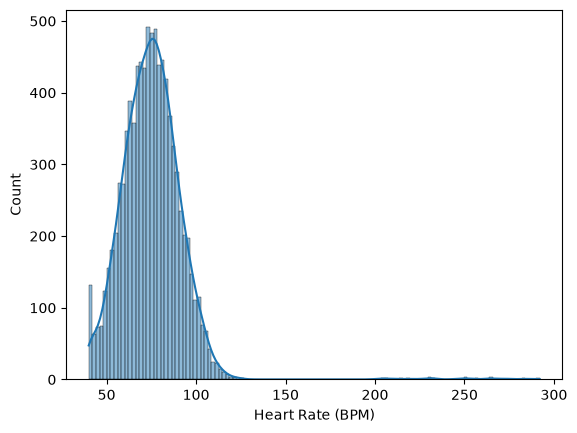

In [9]:
sns.histplot(data=df,x='Heart Rate (BPM)', kde=True)

<Axes: xlabel='Heart Rate (BPM)'>

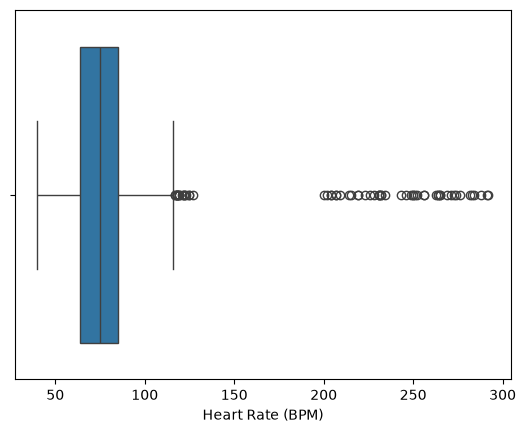

In [10]:
sns.boxplot(data=df,x='Heart Rate (BPM)')

<Axes: xlabel='Blood Oxygen Level (%)', ylabel='Count'>

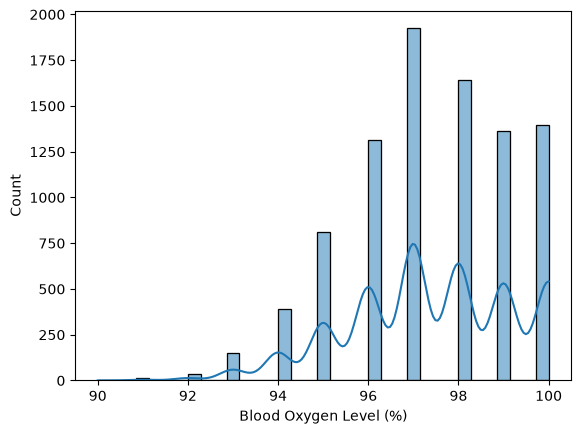

In [11]:
sns.histplot(data=df,x='Blood Oxygen Level (%)', kde=True)

<Axes: xlabel='Blood Oxygen Level (%)'>

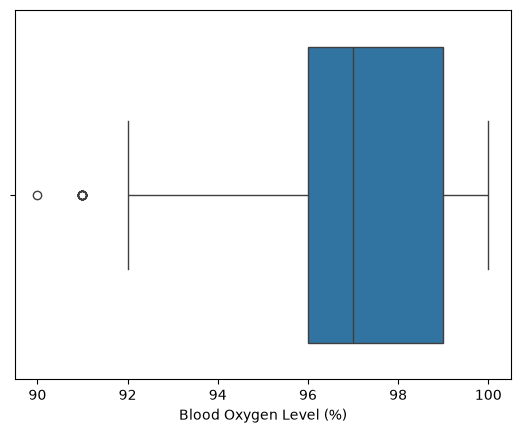

In [12]:
sns.boxplot(data=df,x='Blood Oxygen Level (%)')

<Axes: xlabel='Step Count', ylabel='Count'>

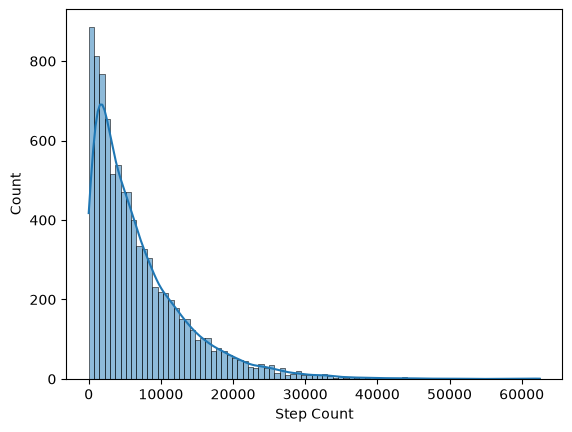

In [13]:
sns.histplot(data=df,x='Step Count', kde=True)

<Axes: xlabel='Step Count'>

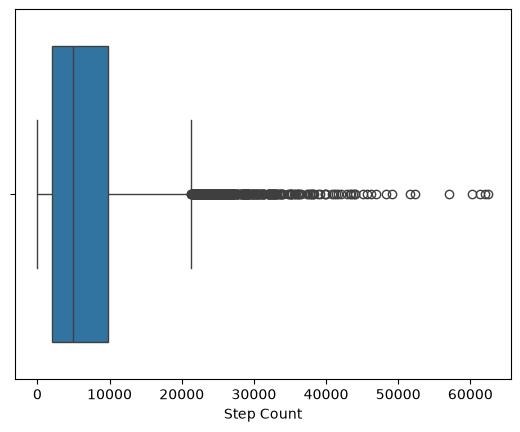

In [14]:
sns.boxplot(data=df,x='Step Count')

<Axes: xlabel='Sleep Duration (hours)', ylabel='Count'>

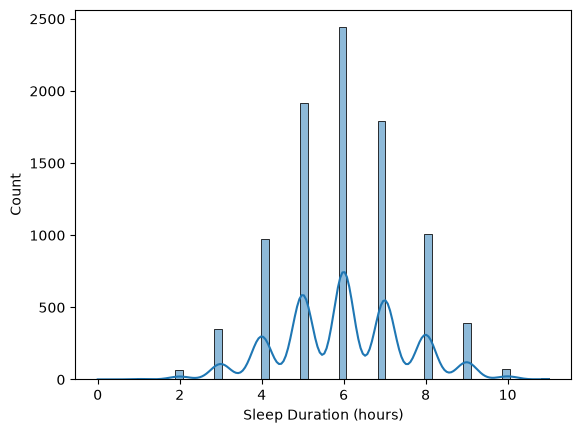

In [15]:
sns.histplot(data=df,x='Sleep Duration (hours)', kde=True)

<Axes: xlabel='Sleep Duration (hours)'>

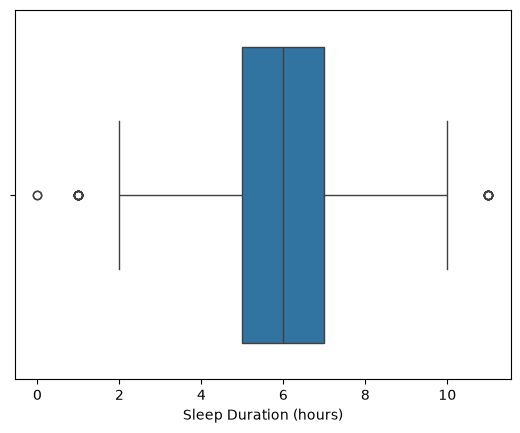

In [16]:
sns.boxplot(data=df,x='Sleep Duration (hours)')

([0, 1, 2, 3, 4, 5],
 [Text(0, 0, 'Highly Active'),
  Text(1, 0, 'Actve'),
  Text(2, 0, 'Highly_Active'),
  Text(3, 0, 'Seddentary'),
  Text(4, 0, 'Sedentary'),
  Text(5, 0, 'Active')])

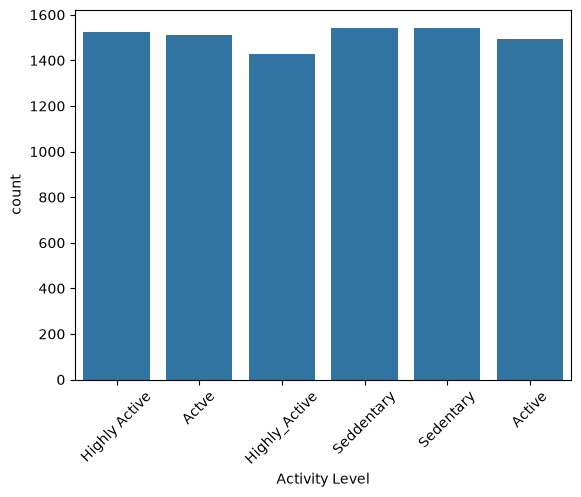

In [17]:
sns.countplot(data=df,x='Activity Level')
plt.xticks(rotation=45)

<Axes: xlabel='Health Risk', ylabel='Count'>

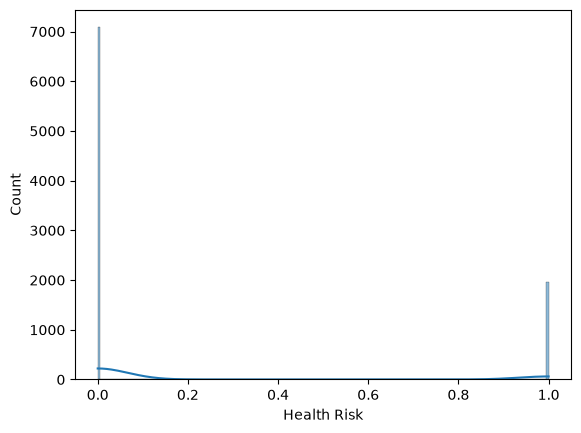

In [18]:
sns.histplot(data=df,x='Health Risk', kde=True)

<Axes: xlabel='Health Risk'>

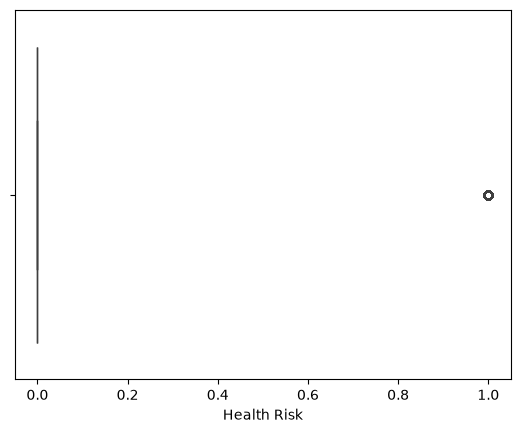

In [19]:
sns.boxplot(data=df,x='Health Risk')

<Axes: xlabel='Stress Level', ylabel='Count'>

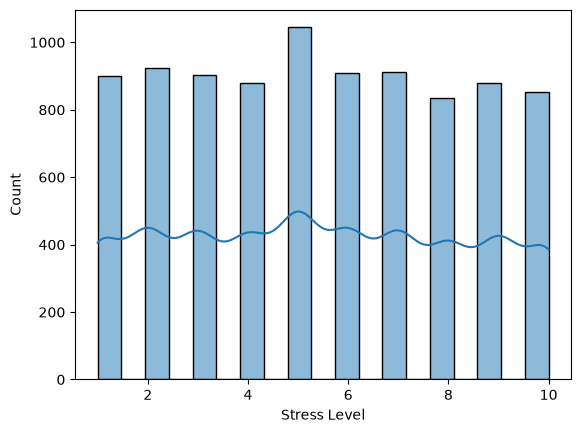

In [20]:
sns.histplot(data=df,x='Stress Level', kde=True)

<Axes: xlabel='Stress Level'>

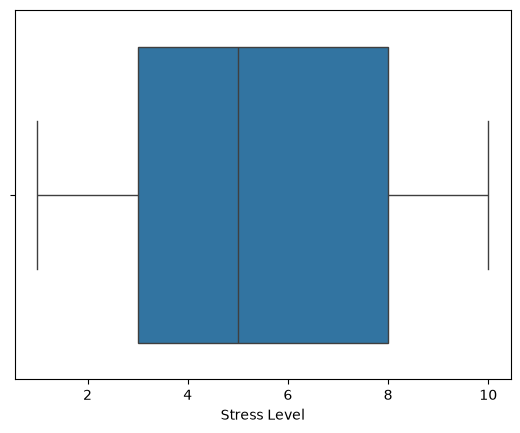

In [21]:
sns.boxplot(data=df,x='Stress Level')

In [22]:
df.head()

,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level,Health Risk
0,58,98,5450,7,Highly Active,1,0
1,40,96,13797,7,Actve,3,0
2,61,98,15679,6,Highly_Active,6,0
3,96,94,10205,8,Highly_Active,10,1
4,47,95,3208,7,Seddentary,2,0


In [23]:
## bivariate analysis

<Axes: xlabel='Heart Rate (BPM)', ylabel='Health Risk'>

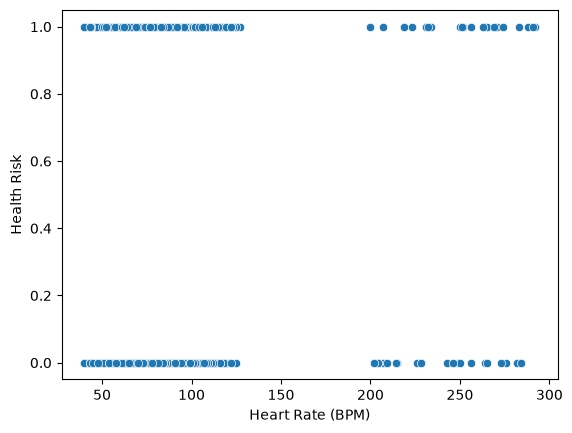

In [24]:
sns.scatterplot(data=df,x='Heart Rate (BPM)',y='Health Risk')

<Axes: xlabel='Blood Oxygen Level (%)', ylabel='Activity Level'>

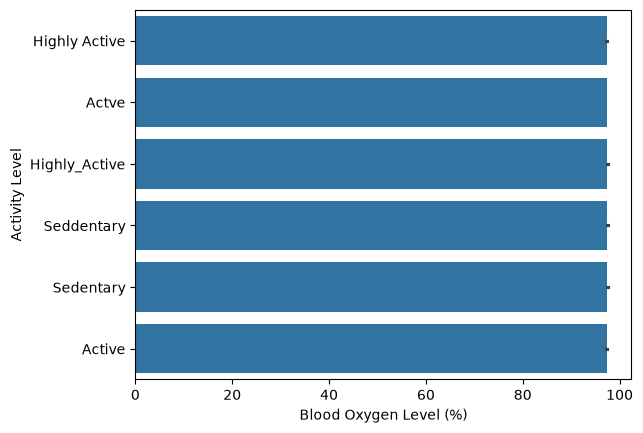

In [25]:
sns.barplot(data=df,x='Blood Oxygen Level (%)',y='Activity Level')

<Axes: xlabel='Stress Level', ylabel='Sleep Duration (hours)'>

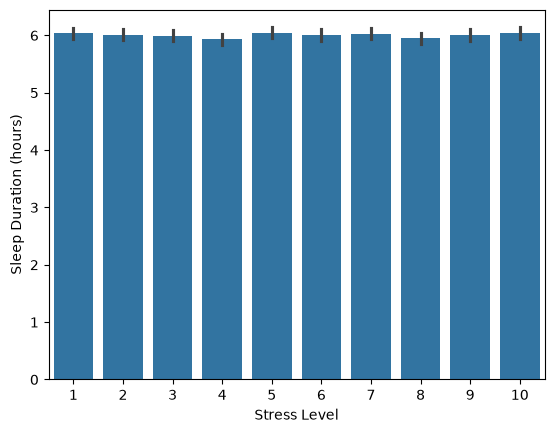

In [26]:
sns.barplot(data=df,x='Stress Level',y='Sleep Duration (hours)')

<Axes: xlabel='Stress Level', ylabel='Heart Rate (BPM)'>

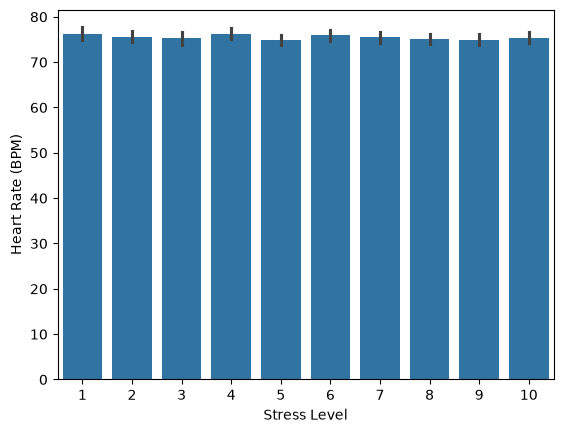

In [27]:
sns.barplot(data=df,x='Stress Level',y='Heart Rate (BPM)')

In [28]:
## feature engineering

In [29]:
df.head()

,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level,Health Risk
0,58,98,5450,7,Highly Active,1,0
1,40,96,13797,7,Actve,3,0
2,61,98,15679,6,Highly_Active,6,0
3,96,94,10205,8,Highly_Active,10,1
4,47,95,3208,7,Seddentary,2,0


In [30]:
df['Activity Level'].value_counts()

Activity Level
Seddentary       1544
Sedentary        1541
Highly Active    1523
Actve            1510
Active           1493
Highly_Active    1429
Name: count, dtype: int64

In [31]:
df["Activity Level"] = (
    df["Activity Level"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace("_", " ")
)

df["Activity Level"] = df["Activity Level"].replace({
    "actve": "active",
    "seddentary": "sedentary",
    "highly active": "highly active"
})


In [32]:
pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [33]:
from sklearn.preprocessing import OrdinalEncoder

In [34]:
oe=OrdinalEncoder(categories=[['sedentary', 'active', 'highly active']])

In [35]:
df['Activity Level'] = oe.fit_transform(df[['Activity Level']])

In [36]:
df.head()

,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level,Health Risk
0,58,98,5450,7,2.0,1,0
1,40,96,13797,7,1.0,3,0
2,61,98,15679,6,2.0,6,0
3,96,94,10205,8,2.0,10,1
4,47,95,3208,7,0.0,2,0


In [37]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

In [38]:
X = df.drop(columns=['Health Risk'])
Y = df['Health Risk']

In [39]:
train_X, test_X, train_Y, test_Y = train_test_split(X, Y, test_size=0.2, random_state=42)

In [40]:
lr=LogisticRegression(random_state=42, max_iter=100)
lr.fit(train_X, train_Y)
y_pred=lr.predict(test_X)
print(classification_report(test_Y, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.95      0.91      1393
           1       0.76      0.57      0.65       415

    accuracy                           0.86      1808
   macro avg       0.82      0.76      0.78      1808
weighted avg       0.85      0.86      0.85      1808



C:\Users\siddhesh\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [41]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [42]:
print("Accuracy:", accuracy_score(test_Y, y_pred))

Accuracy: 0.860066371681416


In [43]:
from sklearn.ensemble import RandomForestClassifier

In [44]:
re=RandomForestClassifier(n_estimators=100, random_state=42)

In [45]:
re.fit(train_X, train_Y)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [46]:
y_pred=re.predict(test_X) 

In [47]:
confusion_mat = confusion_matrix(test_Y, y_pred)

In [48]:
confusion_mat 

array([[1393,    0],
       [   0,  415]])

In [49]:
print(classification_report(test_Y, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1393
           1       1.00      1.00      1.00       415

    accuracy                           1.00      1808
   macro avg       1.00      1.00      1.00      1808
weighted avg       1.00      1.00      1.00      1808



In [50]:
df["Health Risk"].value_counts()

Health Risk
0    7082
1    1958
Name: count, dtype: int64

In [51]:
df.head()

,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level,Health Risk
0,58,98,5450,7,2.0,1,0
1,40,96,13797,7,1.0,3,0
2,61,98,15679,6,2.0,6,0
3,96,94,10205,8,2.0,10,1
4,47,95,3208,7,0.0,2,0


In [52]:
from sklearn.tree import DecisionTreeClassifier

In [53]:
tree=DecisionTreeClassifier(random_state=42, max_depth=5)

In [54]:
tree.fit(train_X, train_Y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [55]:
y_pred=tree.predict(test_X)

In [56]:
print(classification_report(test_Y, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1393
           1       1.00      1.00      1.00       415

    accuracy                           1.00      1808
   macro avg       1.00      1.00      1.00      1808
weighted avg       1.00      1.00      1.00      1808



In [57]:
pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [58]:
from xgboost import XGBClassifier

In [59]:
xb=XGBClassifier(random_state=42, max_depth=5, n_estimators=100,class_weight='balanced')

In [60]:
xb.fit(train_X, train_Y)

C:\Users\siddhesh\AppData\Roaming\Python\Python314\site-packages\xgboost\training.py:200: UserWarning: [12:57:30] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "class_weight" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [61]:
y_pred=xb.predict(test_X)

In [62]:
print(classification_report(test_Y, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1393
           1       1.00      1.00      1.00       415

    accuracy                           1.00      1808
   macro avg       1.00      1.00      1.00      1808
weighted avg       1.00      1.00      1.00      1808



## baseline model comparision 

In [63]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [64]:
models ={'tree': tree, 'randomforest':re, 'xb': xb, 'logistic_regression': lr}

In [65]:
results = []

In [66]:
for name, model in models.items():

    # Predictions
    y_pred = model.predict(test_X)

    # Probability predictions for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(test_X)[:, 1]
    else:
        y_prob = None

    # Metrics
    accuracy = accuracy_score(test_Y, y_pred)
    precision = precision_score(test_Y, y_pred, zero_division=0)
    recall = recall_score(test_Y, y_pred, zero_division=0)
    f1 = f1_score(test_Y, y_pred, zero_division=0)

    if y_prob is not None:
        roc_auc = roc_auc_score(test_Y, y_prob)
    else:
        roc_auc = None

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ])

# Create comparison DataFrame
comparison_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ]
)

# Display results
comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,tree,1.000000,1.000000,1.000000,1.000000,1.00000
1,randomforest,1.000000,1.000000,1.000000,1.000000,1.00000
2,xb,1.000000,1.000000,1.000000,1.000000,1.00000
3,logistic_regression,0.860066,0.757962,0.573494,0.652949,0.88364


## crossvalidation 

In [67]:
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd
import numpy as np

#### 3 perform 5 fold accros validation 

In [68]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        train_X,
        train_Y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_df = pd.DataFrame(cv_results)

cv_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,tree,0.9994,1.0000,0.9974,0.9987,0.9994
1,randomforest,0.9992,1.0000,0.9961,0.9980,1.0000
2,xb,0.9994,1.0000,0.9974,0.9987,1.0000
3,logistic_regression,0.8707,0.7728,0.5606,0.6490,0.8785


#### 4  display perscentage 

In [69]:
cv_percentage = cv_df.copy()
cv_percentage.iloc[:, 1:] = cv_percentage.iloc[:, 1:] * 100
cv_percentage.round(2)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,tree,99.94,100.00,99.74,99.87,99.94
1,randomforest,99.92,100.00,99.61,99.80,100.00
2,xb,99.94,100.00,99.74,99.87,100.00
3,logistic_regression,87.07,77.28,56.06,64.90,87.85


#### 5.veration across folds (mean and std)

In [70]:
for name, model in models.items():

    scores = cross_validate(
        model,
        train_X,
        train_Y,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    print(f"\n{name}")
    print("Fold Accuracy:", scores["test_score"])
    print("Mean:", scores["test_score"].mean())
    print("Std:", scores["test_score"].std())


tree
Fold Accuracy: [0.99861783 1.         1.         1.         0.99861687]
Mean: 0.999446940825727
Std: 0.0006773564547101543

randomforest
Fold Accuracy: [0.99723566 1.         1.         0.99930844 0.99930844]
Mean: 0.9991705068243449
Std: 0.0010156573879202201

xb
Fold Accuracy: [0.99723566 1.         1.         1.         1.        ]
Mean: 0.9994471319972357
Std: 0.0011057360055287012

logistic_regression
Fold Accuracy: [0.86454734 0.86800276 0.87413555 0.86445367 0.8824343 ]
Mean: 0.8707147233604893
Std: 0.006835828229737506


## hyperparameter tuning 

In [71]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

In [72]:
## logistic regression hyperparameter tuning
lr_params = {
    "C": loguniform(0.001, 100),
    "solver": ["liblinear", "lbfgs"],
    "max_iter": [500, 1000, 2000]
}

lr_search = RandomizedSearchCV(
    estimator=lr,
    param_distributions=lr_params,
    n_iter=20,
    cv=5,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)

lr_search.fit(train_X, train_Y)

print("Best Parameters:", lr_search.best_params_)
print("Best CV Score:", lr_search.best_score_)

Best Parameters: {'C': np.float64(0.17885301261862016), 'max_iter': 1000, 'solver': 'lbfgs'}
Best CV Score: 0.6725954278551185


In [73]:
tree_params = {
    "max_depth": [3, 5, 7, 10, 15, 20, None],
    "min_samples_split": randint(2, 20),
    "min_samples_leaf": randint(1, 10),
    "criterion": ["gini", "entropy", "log_loss"],
    "max_features": ["sqrt", "log2", None]
}

dtc_search = RandomizedSearchCV(
    estimator=tree,
    param_distributions=tree_params,
    n_iter=30,
    cv=5,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)

dtc_search.fit(train_X, train_Y)

print("Best Parameters:", dtc_search.best_params_)
print("Best CV Score:", dtc_search.best_score_)

Best Parameters: {'criterion': 'log_loss', 'max_depth': 7, 'max_features': None, 'min_samples_leaf': 3, 'min_samples_split': 13}
Best CV Score: 1.0


In [74]:
## Hyperparameter tuning for Random Forest
re_params = {
    "n_estimators": randint(100, 500),
    "max_depth": [5, 10, 15, 20, 30, None],
    "min_samples_split": randint(2, 15),
    "min_samples_leaf": randint(1, 8),
    "max_features": ["sqrt", "log2", None],
    "criterion": ["gini", "entropy", "log_loss"]
}

rfc_search = RandomizedSearchCV(
    estimator=re,
    param_distributions=re_params,
    n_iter=30,
    cv=5,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)

rfc_search.fit(train_X, train_Y)

print("Best Parameters:", rfc_search.best_params_)
print("Best CV Score:", rfc_search.best_score_)

Best Parameters: {'criterion': 'gini', 'max_depth': 30, 'max_features': None, 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 314}
Best CV Score: 1.0


In [75]:
## Hyperparameter tuning for XGBoost
xb_params = {
    "n_estimators": randint(100, 500),
    "max_depth": randint(3, 12),
    "learning_rate": uniform(0.01, 0.29),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "min_child_weight": randint(1, 10),
    "gamma": uniform(0, 0.5)
}

xgbc_search = RandomizedSearchCV(
    estimator=xb,
    param_distributions=xb_params,
    n_iter=30,
    cv=5,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)

xgbc_search.fit(train_X, train_Y)

print("Best Parameters:", xgbc_search.best_params_)
print("Best CV Score:", xgbc_search.best_score_)

C:\Users\siddhesh\AppData\Roaming\Python\Python314\site-packages\xgboost\training.py:200: UserWarning: [12:58:48] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "class_weight" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best Parameters: {'colsample_bytree': np.float64(0.749816047538945), 'gamma': np.float64(0.4753571532049581), 'learning_rate': np.float64(0.22227824312530747), 'max_depth': 7, 'min_child_weight': 7, 'n_estimators': 221, 'subsample': np.float64(0.662397808134481)}
Best CV Score: 1.0


In [76]:
## get the best tune model 
best_models = {
    "Logistic Regression": lr_search.best_estimator_,
    "Decision Tree": dtc_search.best_estimator_,
    "Random Forest": rfc_search.best_estimator_,
    "XGBoost": xgbc_search.best_estimator_
}

In [77]:
## compare the best tuned models
tuned_results = []

for name, model in best_models.items():

    y_pred = model.predict(train_X)

    y_prob = model.predict_proba(train_X)[:, 1]

    tuned_results.append({
        "Model": name, 
        "Accuracy": accuracy_score(train_Y, y_pred),
        "Precision": precision_score(train_Y, y_pred, zero_division=0),
        "Recall": recall_score(train_Y, y_pred, zero_division=0),
        "F1 Score": f1_score(train_Y, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(train_Y, y_prob)
    })

tuned_df = pd.DataFrame(tuned_results)

tuned_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8756,0.7722,0.5911,0.6696,0.8966
1,Decision Tree,1.0000,1.0000,1.0000,1.0000,1.0000
2,Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000
3,XGBoost,1.0000,1.0000,1.0000,1.0000,1.0000


## SHAP

In [78]:
pip install shap -q 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [79]:
import shap 
import matplotlib.pyplot as plt

In [81]:
shap_explainers = {}
shap_values = {}

for name, model in best_models.items():

    print(f"Generating SHAP for: {name}")

    if name == "Logistic Regression":
        explainer = shap.LinearExplainer(model, train_X)

    else:
        explainer = shap.TreeExplainer(model)

    values = explainer(test_X)

    shap_explainers[name] = explainer
    shap_values[name] = values

    print(f"Completed: {name}")

Background dataset has 7232 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=7232 when initializing the masker.


Generating SHAP for: Logistic Regression
Completed: Logistic Regression
Generating SHAP for: Decision Tree
Completed: Decision Tree
Generating SHAP for: Random Forest
Completed: Random Forest
Generating SHAP for: XGBoost
Completed: XGBoost



Logistic Regression
SHAP shape: (1808, 6)
Test X shape: (1808, 6)


,Feature,SHAP Importance
5,Stress Level,1.452439
3,Sleep Duration (hours),1.329778
1,Blood Oxygen Level (%),0.517469
0,Heart Rate (BPM),0.129949
2,Step Count,0.022604
4,Activity Level,0.006973


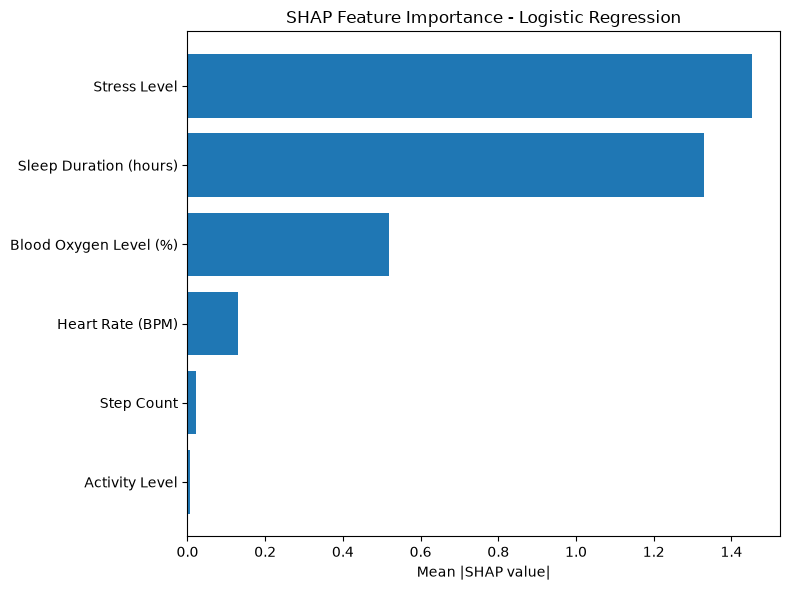


Decision Tree
SHAP shape: (1808, 6, 2)
Test X shape: (1808, 6)


,Feature,SHAP Importance
3,Sleep Duration (hours),0.197529
5,Stress Level,0.194003
0,Heart Rate (BPM),0.076306
1,Blood Oxygen Level (%),0.059009
2,Step Count,0.000000
4,Activity Level,0.000000


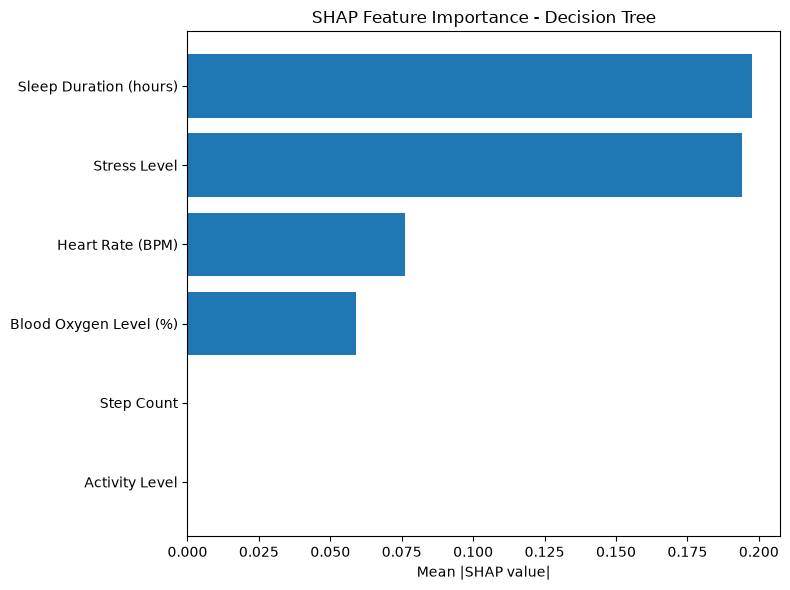


Random Forest
SHAP shape: (1808, 6, 2)
Test X shape: (1808, 6)


,Feature,SHAP Importance
3,Sleep Duration (hours),0.197502
5,Stress Level,0.193801
0,Heart Rate (BPM),0.076231
1,Blood Oxygen Level (%),0.058892
2,Step Count,0.000006
4,Activity Level,0.000002


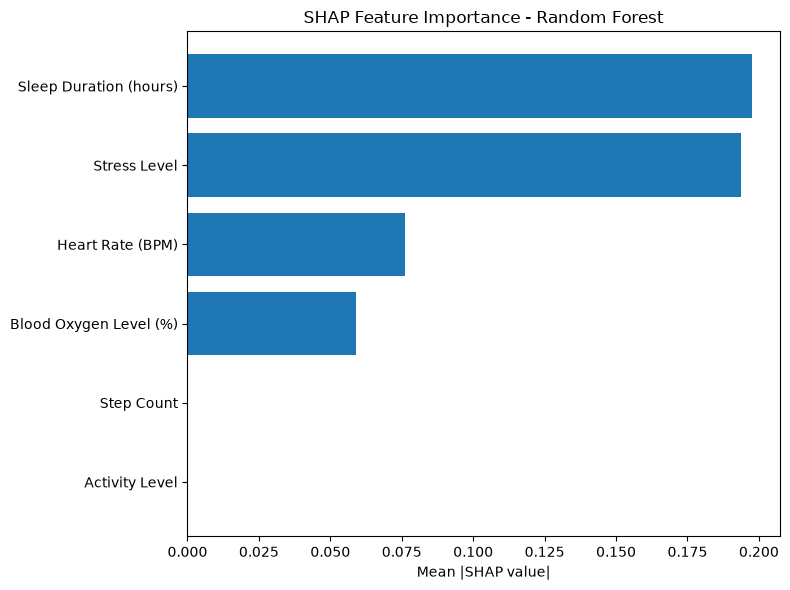


XGBoost
SHAP shape: (1808, 6)
Test X shape: (1808, 6)


,Feature,SHAP Importance
5,Stress Level,4.517385
3,Sleep Duration (hours),4.462626
0,Heart Rate (BPM),2.691002
1,Blood Oxygen Level (%),2.051146
2,Step Count,0.044118
4,Activity Level,0.008641


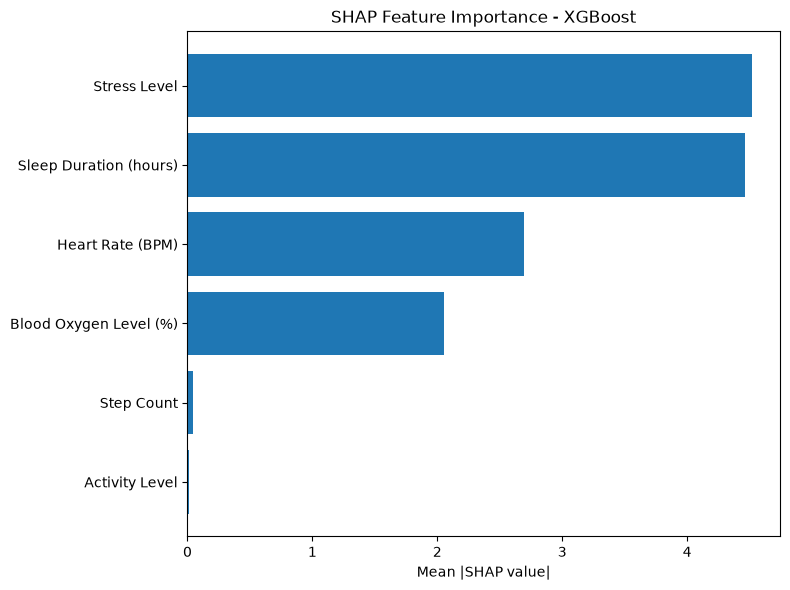

In [87]:
for name, values in shap_values.items():

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    # Get the actual SHAP values
    shap_array = values.values

    print("SHAP shape:", shap_array.shape)
    print("Test X shape:", test_X.shape)

    # Handle different SHAP output formats
    if shap_array.ndim == 2:
        # Shape: (samples, features)
        importance = np.abs(shap_array).mean(axis=0)

    elif shap_array.ndim == 3:
        # Shape can be:
        # (samples, features, classes)
        # Take mean absolute SHAP across samples AND classes
        importance = np.abs(shap_array).mean(axis=(0, 2))

    else:
        raise ValueError(
            f"Unexpected SHAP array shape: {shap_array.shape}"
        )

    # Make sure importance is 1-dimensional
    importance = np.asarray(importance).flatten()

    # Check feature/importance lengths
    if len(importance) != len(test_X.columns):
        raise ValueError(
            f"Number of features ({len(test_X.columns)}) "
            f"does not match SHAP importance values ({len(importance)}). "
            f"SHAP shape: {shap_array.shape}"
        )

    feature_importance = pd.DataFrame({
        "Feature": test_X.columns,
        "SHAP Importance": importance
    })

    feature_importance = feature_importance.sort_values(
        "SHAP Importance",
        ascending=False
    )

    display(feature_importance.head(15))

    # Plot top 15 features
    top_features = feature_importance.head(15).sort_values(
        "SHAP Importance"
    )

    plt.figure(figsize=(8, 6))

    plt.barh(
        top_features["Feature"],
        top_features["SHAP Importance"]
    )

    plt.xlabel("Mean |SHAP value|")
    plt.title(f"SHAP Feature Importance - {name}")
    plt.tight_layout()
    plt.show()


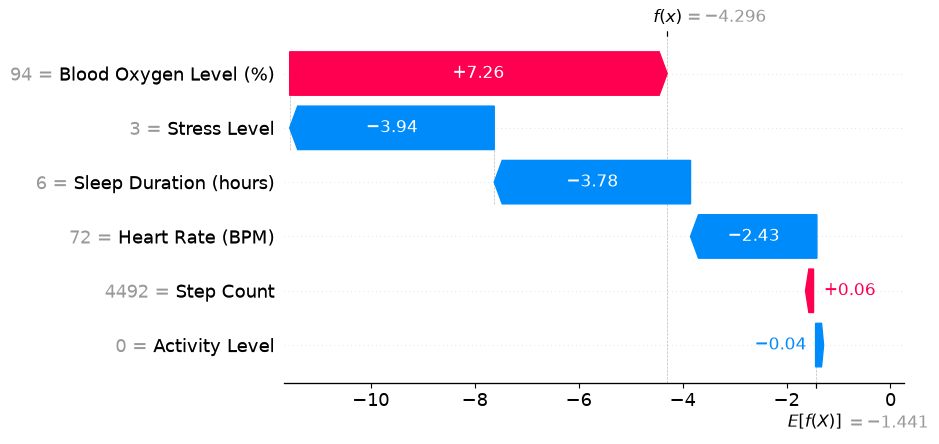

In [90]:
xgb_shap_values = shap_values["XGBoost"]
shap.plots.waterfall(
    xgb_shap_values[10], max_display=15 )


Logistic Regression
SHAP shape: (1808, 6)


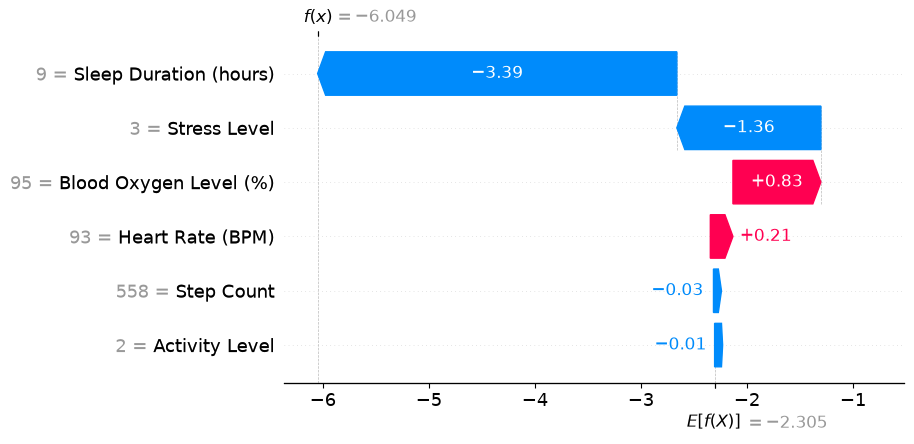


Decision Tree
SHAP shape: (1808, 6, 2)

Class 0


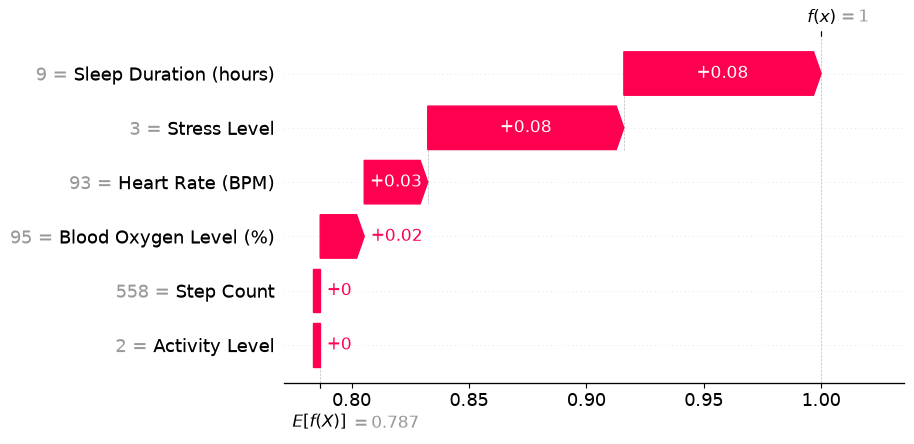


Class 1


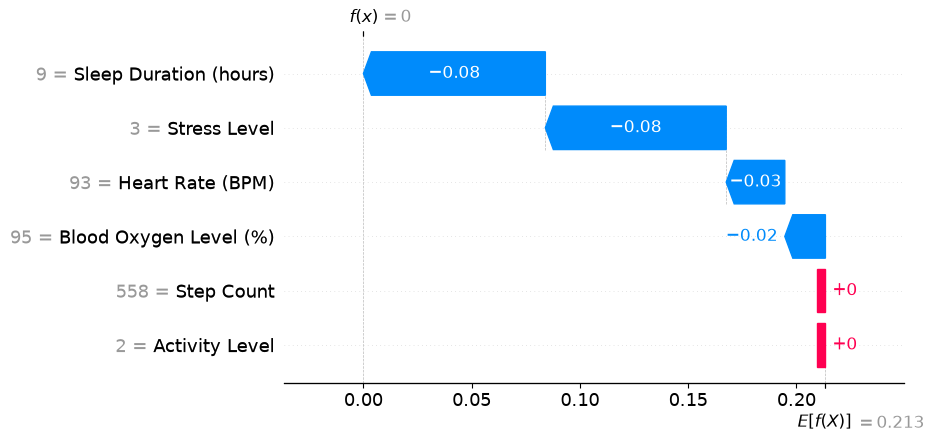


Random Forest
SHAP shape: (1808, 6, 2)

Class 0


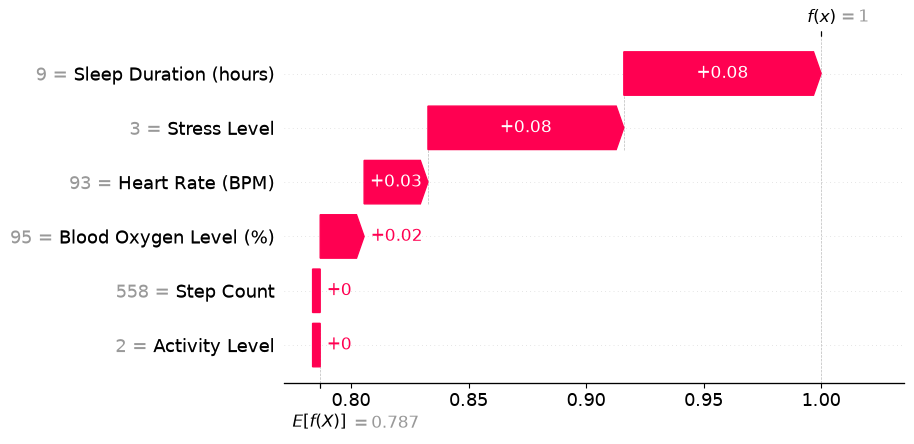


Class 1


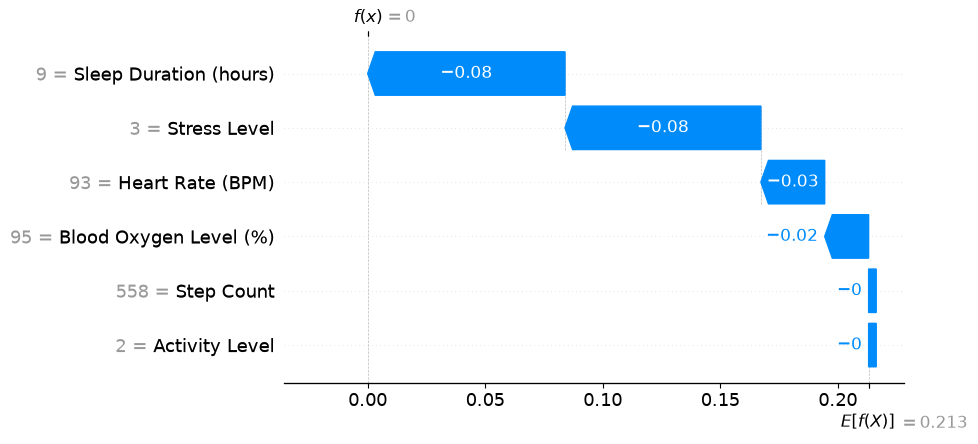


XGBoost
SHAP shape: (1808, 6)


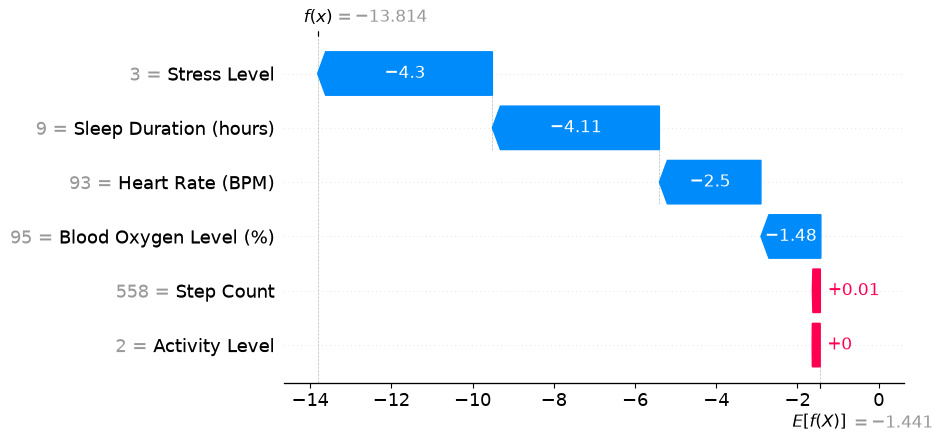

In [94]:
index = 0

for name, values in shap_values.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("SHAP shape:", values.values.shape)

    # Get one sample
    sample = values[index]

    # Multi-output SHAP: (features, classes)
    if sample.values.ndim == 2:

        n_classes = sample.values.shape[1]

        for class_index in range(n_classes):
            print(f"\nClass {class_index}")

            shap.plots.waterfall(
                sample[:, class_index],
                max_display=15
            )

    # Normal SHAP: (features,)
    else:

        shap.plots.waterfall(
            sample,
            max_display=15
        )


In [95]:
for name, model in best_models.items():
    y_pred = model.predict(test_X)
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

print(classification_report(test_Y, y_pred))


Logistic Regression

Decision Tree

Random Forest

XGBoost
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1393
           1       1.00      1.00      1.00       415

    accuracy                           1.00      1808
   macro avg       1.00      1.00      1.00      1808
weighted avg       1.00      1.00      1.00      1808



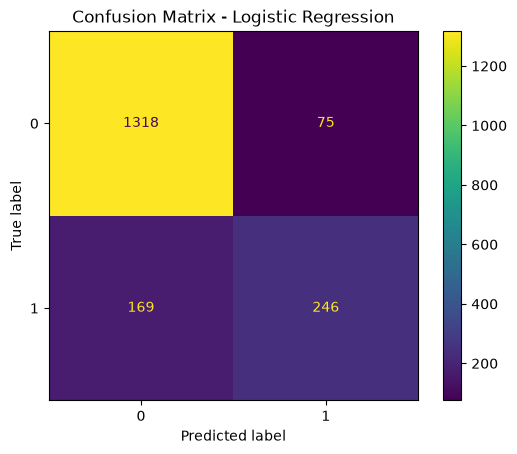

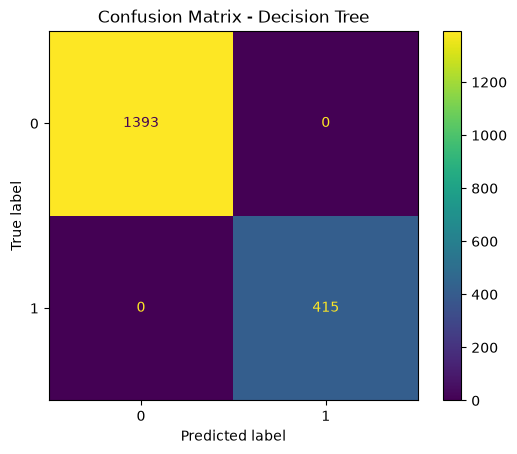

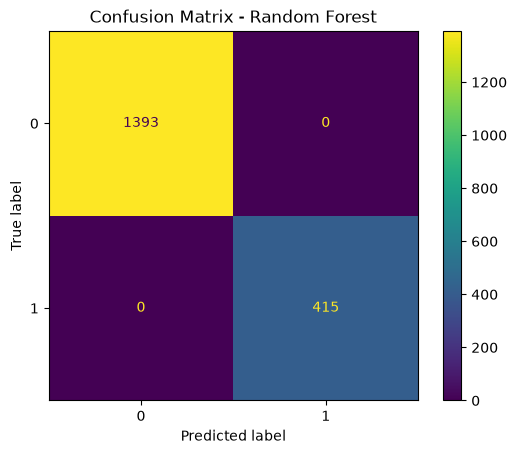

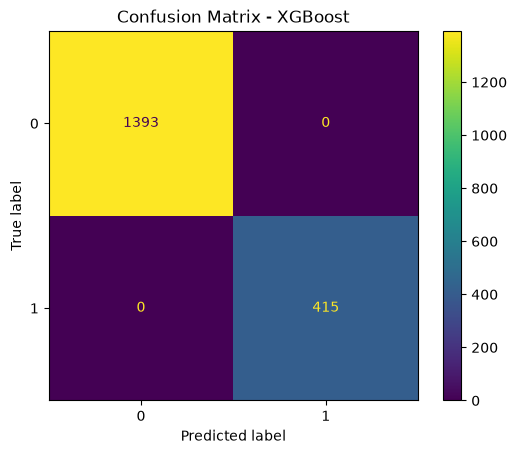

In [97]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in best_models.items():

    y_pred = model.predict(test_X)

    ConfusionMatrixDisplay.from_predictions(
        test_Y,
        y_pred
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.show()

In [98]:
from sklearn.metrics import roc_auc_score

for name, model in best_models.items():

    y_prob = model.predict_proba(test_X)[:, 1]

    auc = roc_auc_score(test_Y, y_prob)

    print(f"{name}: ROC-AUC = {auc:.4f}")

Logistic Regression: ROC-AUC = 0.9036
Decision Tree: ROC-AUC = 1.0000
Random Forest: ROC-AUC = 1.0000
XGBoost: ROC-AUC = 1.0000


In [99]:
pip install joblib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [100]:
best_models 

{'Logistic Regression': LogisticRegression(C=np.float64(0.17885301261862016), max_iter=1000,
                    random_state=42),
 'Decision Tree': DecisionTreeClassifier(criterion='log_loss', max_depth=7, min_samples_leaf=3,
                        min_samples_split=13, random_state=42),
 'Random Forest': RandomForestClassifier(max_depth=30, max_features=None, min_samples_leaf=2,
                        min_samples_split=4, n_estimators=314, random_state=42),
 'XGBoost': XGBClassifier(base_score=None, booster=None, callbacks=None,
               class_weight='balanced', colsample_bylevel=None,
               colsample_bynode=None,
               colsample_bytree=np.float64(0.749816047538945), device=None,
               early_stopping_rounds=None, enable_categorical=True,
               eval_metric=None, feature_types=None, feature_weights=None,
               gamma=np.float64(0.4753571532049581), grow_policy=None,
               importance_type=None, interaction_constraints=None,
  

In [101]:
final_models=best_models['XGBoost']

In [102]:
import joblib 
joblib.dump(final_models, 'Stress_Prediction_Model.pkl')

['Stress_Prediction_Model.pkl']

In [103]:
load_model = joblib.load('Stress_Prediction_Model.pkl')

In [104]:
print(load_model)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              class_weight='balanced', colsample_bylevel=None,
              colsample_bynode=None,
              colsample_bytree=np.float64(0.749816047538945), device=None,
              early_stopping_rounds=None, enable_categorical=True,
              eval_metric=None, feature_types=None, feature_weights=None,
              gamma=np.float64(0.4753571532049581), grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=np.float64(0.22227824312530747), max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=7, max_leaves=None,
              min_child_weight=7, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=221, n_jobs=None, ...)


In [105]:
print(train_X.columns.tolist())

['Heart Rate (BPM)', 'Blood Oxygen Level (%)', 'Step Count', 'Sleep Duration (hours)', 'Activity Level', 'Stress Level']


In [106]:
coustominput= pd.DataFrame([{
    'Heart Rate (BPM)': 75,
    'Blood Oxygen Level (%)': 98,
    'Step Count': 5000,
    'Sleep Duration (hours)': 7,
    'Activity Level': 1,
    'Stress Level': 4
}]) 

In [107]:
prediction = load_model.predict(coustominput)

In [111]:
print(prediction[0])
probability = load_model.predict_proba(coustominput)
print(probability)

0
[[9.999995e-01 4.531858e-07]]
